In [83]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

from pathlib import Path

In [51]:
image_dir = Path("../data/raw")

image_paths = list(image_dir.glob("*.png"))
print("Number of images:", len(image_paths))

image_path = image_paths[3]
print("Image we will work with:", image_path)

Number of images: 4
Image we will work with: ..\data\raw\IMG_0837.png


(np.float64(-0.5), np.float64(3023.5), np.float64(4031.5), np.float64(-0.5))

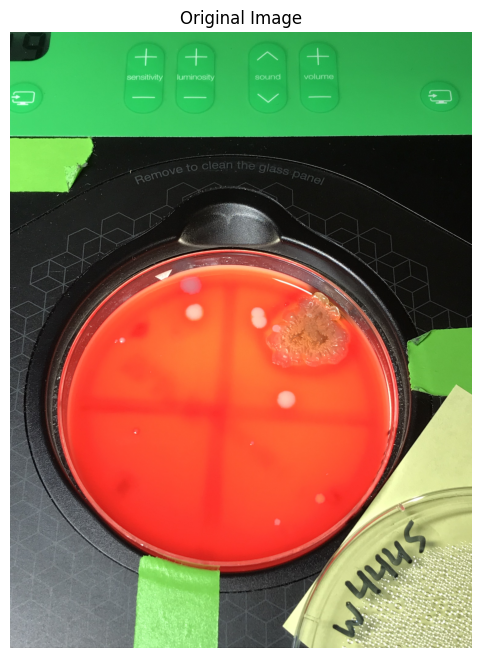

In [52]:
image_bgr = cv2.imread(str(image_path))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

## HSV

Normally, images are RGB. But HSV represents colors differently.

H (Hue) - What color is the pixel

S (Saturation) - How strong or vibrant is that color

V (Value) - How bright or dark is that color

For the petri dish, this is helpful for seperating the red petri dish from the background.

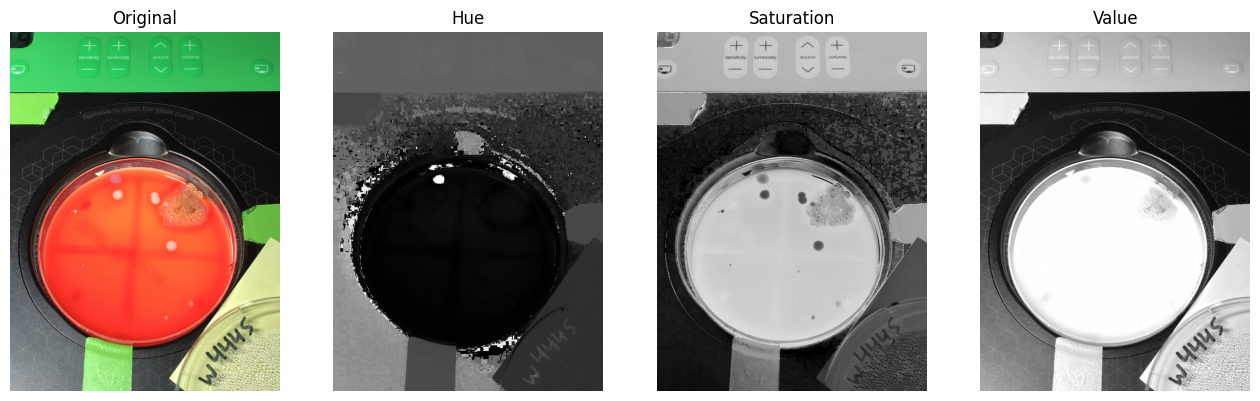

In [42]:
image_hsv = cv2.cvtColor(
    image_bgr,
    cv2.COLOR_BGR2HSV
)

h = image_hsv[:, :, 0]
s = image_hsv[:, :, 1]
v = image_hsv[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original")

axes[1].imshow(h, cmap="gray")
axes[1].set_title("Hue")

axes[2].imshow(s, cmap="gray")
axes[2].set_title("Saturation")

axes[3].imshow(v, cmap="gray")
axes[3].set_title("Value")

for ax in axes:
    ax.axis("off")

plt.show()

## Make a rough plate mask

Because it is red/orange, we can use HSV to identify it.

lower_red1 and upper_red 1 are arrays that find the values of red. So the first elements in the arrays are the hues of 0 and 30. This will filter out any non red/orange colors. That's because red has a value between 0 and 30. The the second elements are the saturation between 40 and 255. This will filter out any gray colors. And the third element is the value which is also between 40 and 255. This will filter out any dark pixels.

cv2.inRange() takes an image, then it checks the lower bounds and upper bounds. If a pixel in the image falls out of bounds, it turns black. If it falls in the bounds, it turns white. What we are doing is taking two images with two different hue value ranges. That's because red is also is the bottom and top parts of the hue. Red ranges from 0-30 and 160-180. Then we combine it into one (plate_mask_raw).

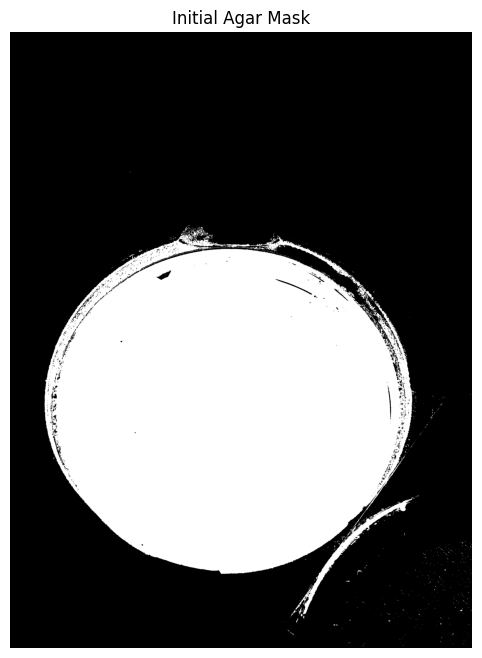

In [43]:
lower_red1 = np.array([0, 40, 40])
upper_red1 = np.array([30, 255, 255])

lower_red2 = np.array([160, 40, 40])
upper_red2 = np.array([179, 255, 255])

mask1 = cv2.inRange(image_hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(image_hsv, lower_red2, upper_red2)

plate_mask_raw = mask1 | mask2

plt.figure(figsize=(8, 8))
plt.imshow(plate_mask_raw, cmap="gray")
plt.title("Initial Agar Mask")
plt.axis("off")
plt.show()

## Morphology Cleanup

The purpose of a morphology cleanup is to improve the mask that we just did with the ranges. What I'm doing here is creating a kernel using cv2.getStructuringElement(). The kernel is going to be an ellipse shape and it's going to be 15x15 pixels. We are using that kernel to slide over the mask that we just made.

Using that kernel, I'm using morphologyEx() (link: **geeksforgeeks.org/computer-vision/different-morphological-operations-in-image-processing/**) which analyzes the spatial relationship between pixels and removes noise from an image. By first closing an image, it fills in the holes and gaps. Then opening an image, it will isolate noise and thin bridges. It's almost like a convolution, but instead of doing mathematical operations on the pixels in the kernel, it does logical operations on them to see if they meet certain conditions.

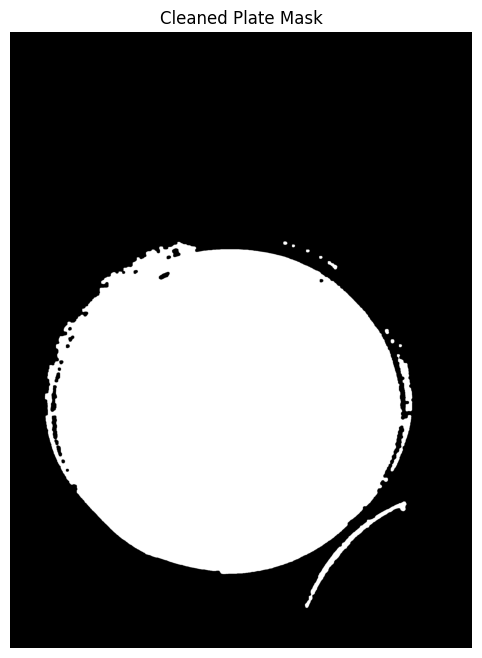

In [44]:
# Swap close and open later

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (20, 20)
)

plate_mask_clean = cv2.morphologyEx(
    plate_mask_raw,
    cv2.MORPH_OPEN,
    kernel
)

plate_mask_clean = cv2.morphologyEx(
    plate_mask_clean,
    cv2.MORPH_CLOSE,
    kernel
)

plt.figure(figsize=(8, 8))
plt.imshow(plate_mask_clean, cmap="gray")
plt.title("Cleaned Plate Mask")
plt.axis("off")
plt.show()

## Contours

A contour is an array of points that trace around the boundary of an object. So doing cv2.findContours(), we will get coordinates of the object. The parameters of the function are simple. cv2.RETR_EXTERNAL gets the external part of the object. For example, if you had a donut and you did RETR_TREE then you would get the inner and outer boundaries of the donut. cv2.CHAIN_APPROX_SIMPLE allows you to not get repetitve points on straight lines.

Largest contour allows you to get the area of the largest contour. This will be used later to get the boundaries of the largest contour.


In [45]:
contours, _ = cv2.findContours(
    plate_mask_clean,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

largest_contour = max(contours, key=cv2.contourArea)

print("Largest plate area:", cv2.contourArea(largest_contour))
print(largest_contour)
for i in range(0, len(contours)):
    print("Contour ", i, " is length:", len(contours[i]))



Largest plate area: 3886803.0
[[[1098 1374]]

 [[1096 1376]]

 [[1096 1384]]

 ...

 [[1113 1376]]

 [[1112 1376]]

 [[1110 1374]]]
Contour  0  is length: 899
Contour  1  is length: 278
Contour  2  is length: 23
Contour  3  is length: 27
Contour  4  is length: 39
Contour  5  is length: 77
Contour  6  is length: 24
Contour  7  is length: 24
Contour  8  is length: 23
Contour  9  is length: 3145
Contour  10  is length: 26


## Drawing the boundaries

cv2.drawContours() draws the boundaries onto an image that we specify. We then give it the coordinates of the petri dish (which should be the largest_contour) so it can draw it on the image. contourIdx = -1 which means draw all contours in the list. We also give it the color we want it to be (0, 255, 0) = green. And then we give it the thickness (10)

Then plot it so we can see the outline of the petri dish

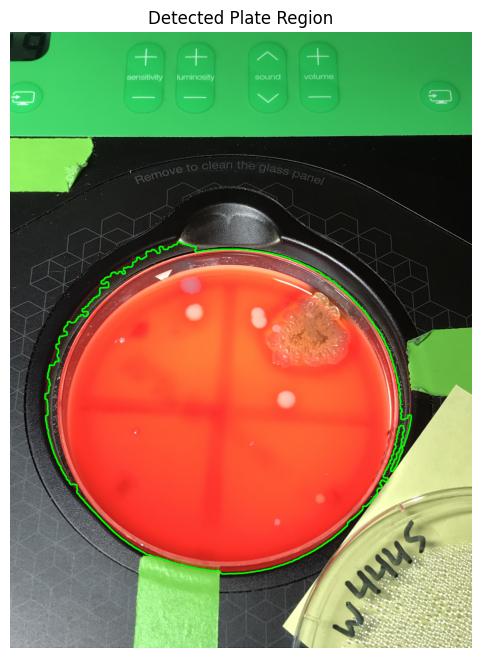

In [46]:
contour_image = image_rgb.copy()

cv2.drawContours(
    contour_image,
    [largest_contour],
    -1,
    (0, 255, 0),
    10
)

plt.figure(figsize=(8, 8))
plt.imshow(contour_image)
plt.title("Detected Plate Region")
plt.axis("off")
plt.show()

## Put an Ellipse on the Petri Dish

This is where we take the contour that we had from the petri dish and put a smooth ellipse on it so it looks nicer. cv2.fitEllipse() takes in a set of 2D points and calculates an ellipse that best fits those points. It returns a tuple ((center_x, center_y), (width, height), rotation_angle).

Then we draw this ellipse onto an image using cv2.ellipse().

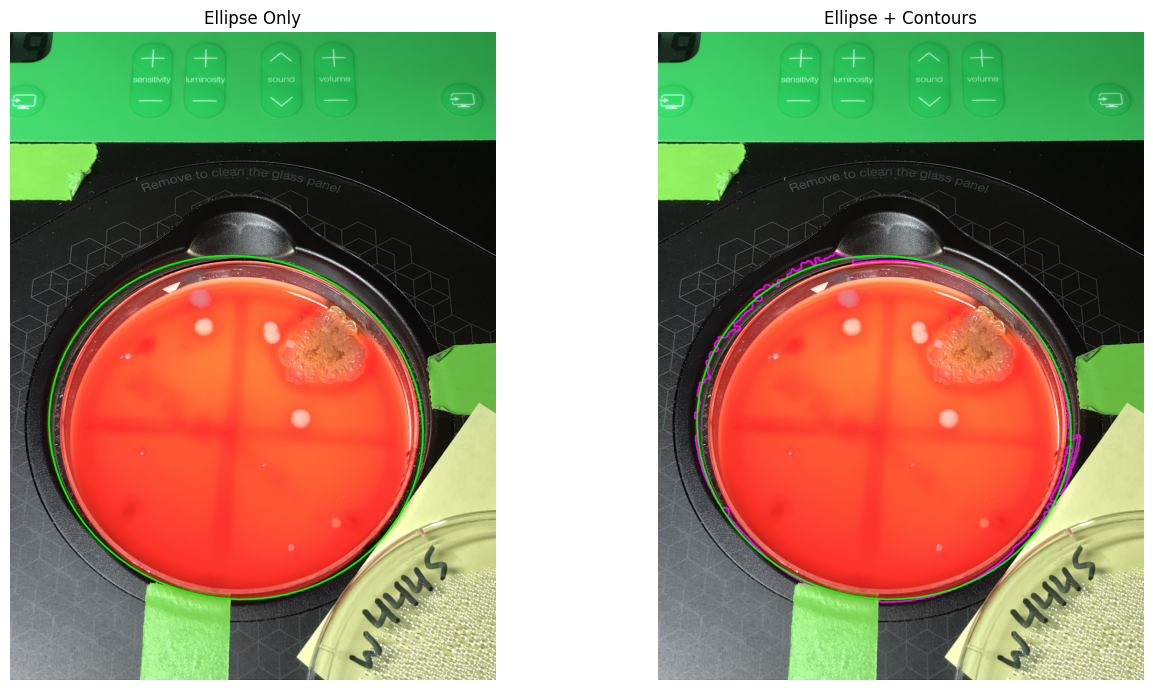

In [47]:
# Fit ellipse to contour
ellipse = cv2.fitEllipse(largest_contour)

# Image 1: Only ellipse
ellipse_only = image_rgb.copy()

cv2.ellipse(
    ellipse_only,
    ellipse,
    (0, 255, 0),
    10
)

# Image 2: Ellipse + contours
ellipse_contours = image_rgb.copy()

cv2.drawContours(
    ellipse_contours,
    [largest_contour],
    -1,
    (255, 0, 255),
    10
)

cv2.ellipse(
    ellipse_contours,
    ellipse,
    (0, 255, 0),
    10
)

# Plot both images side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(ellipse_only)
axes[0].set_title("Ellipse Only")
axes[0].axis("off")

axes[1].imshow(ellipse_contours)
axes[1].set_title("Ellipse + Contours")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Create the final petri dish mask

By using np.zeros(), we make an all black image the size of the original image. We get that size from image_rgb.shape[:2]. When we add the ellipse from earlier and make it all white (255).

You have to make sure the dtype is np.uint8. If you don't, np.zeros() defaults to float64 which is not valid for the later function cv2.bitwise_and().

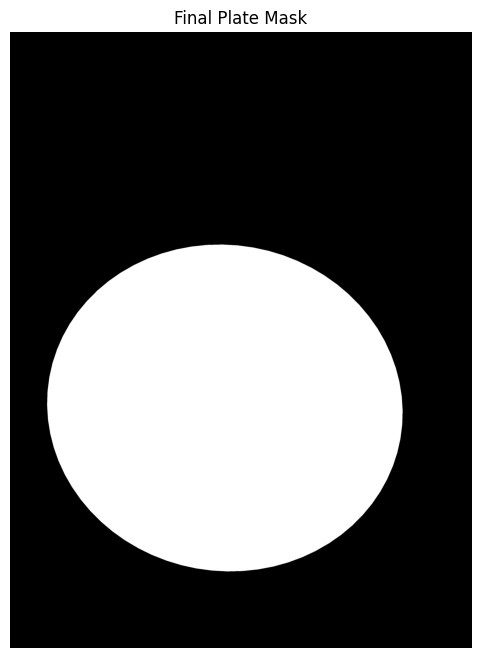

In [48]:
final_plate_mask = np.zeros(
    image_rgb.shape[:2],
    dtype=np.uint8
)

cv2.ellipse(
    final_plate_mask,
    ellipse,
    255,
    -1
)

plt.figure(figsize=(8, 8))
plt.imshow(final_plate_mask, cmap="gray")
plt.title("Final Plate Mask")
plt.axis("off")
plt.show()

## Final segmentation

Using the cv2.bitwise_and() function, we can add in our original image and use the final_plate_mask to filter out the black space. We could also get the same thing by doing segmented_plate[final_plate_mask == 0] = 0. This would also filter out anything that's not the petri dish.

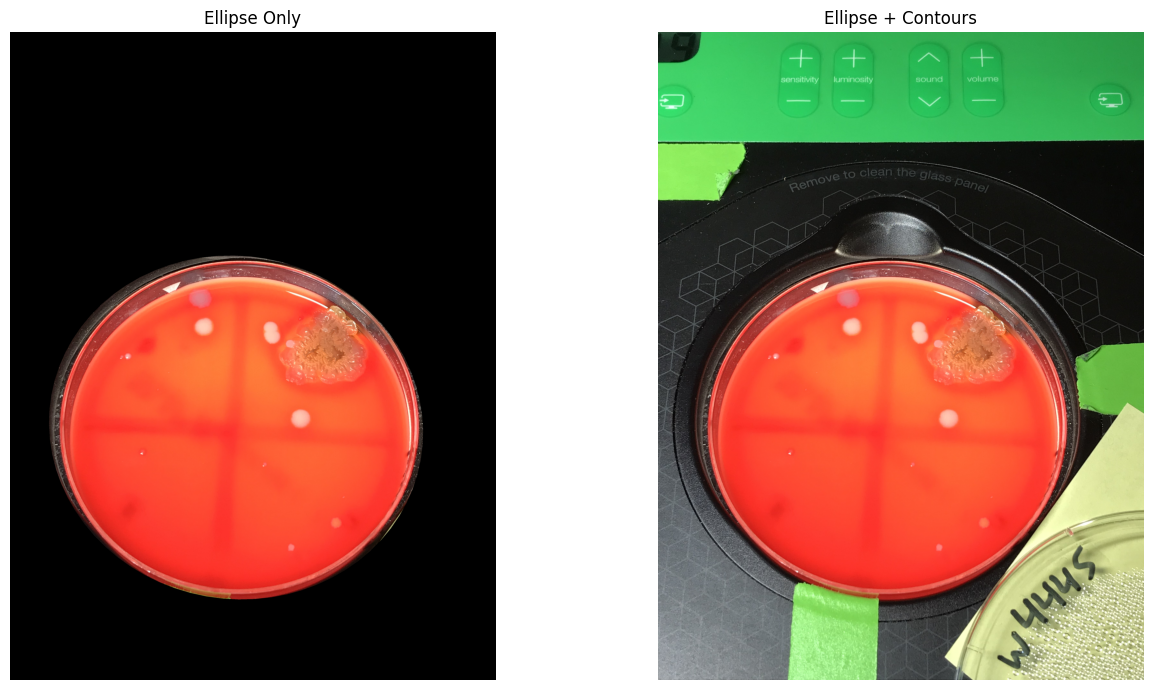

In [49]:
segmented_plate = cv2.bitwise_and(
    image_rgb,
    image_rgb,
    mask=final_plate_mask
)

# This would also work
# segmented_plate = image_rgb.copy()
# segmented_place[final_plate_mask==0] = 0

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(segmented_plate)
axes[0].set_title("Ellipse Only")
axes[0].axis("off")

axes[1].imshow(image_rgb)
axes[1].set_title("Ellipse + Contours")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Cropping

Crop the image

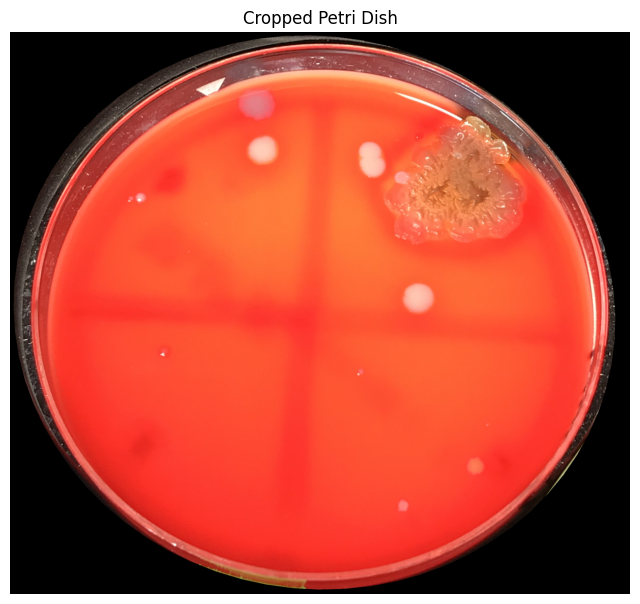

In [53]:
x, y, w, h = cv2.boundingRect(largest_contour)

cropped_plate = segmented_plate[
    y:y+h,
    x:x+w
]

plt.figure(figsize=(8, 8))
plt.imshow(cropped_plate)
plt.title("Cropped Petri Dish")
plt.axis("off")
plt.show()

## Save to segmented data folder

In [ ]:
output_dir = r"..\data\segmented"
# I have to cheat and remove the "I" because the last backslash won't get deleted if I don't put anything infront of it
name = str(image_path).replace(r"..\data\raw\I", "").replace(".png", "")
file_name = f"I{name}_segmented.png"
print("File name:", file_name)

# os.makedirs(output_dir, exist_ok=True)
full_path = os.path.join(output_dir, file_name)
print("Path to send:", full_path)

cropped_plate_bgr = cv2.cvtColor(cropped_plate, cv2.COLOR_RGB2BGR)
# Read and save using OpenCV
cv2.imwrite(full_path, cropped_plate_bgr)

File name: IMG_0837_segmented.png
Path to send: ..\data\segmented\IMG_0837_segmented.png


True